<a href="https://colab.research.google.com/github/Shopska/Personalized_analysis_of_social_media/blob/main/03_feature_engineering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 — Feature Engineering

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Shopska/Personalized_analysis_of_social_media/blob/main/notebooks/03-feature-engineering.ipynb)

**Goal** – Turn the raw tables into a leakage-safe feature table for the global and per-creator models.

**Input** – `data/raw/*.parquet`, decisions from notebooks 01–02, settings from `config/default.yaml`. All feature code lives in `src/creator_analytics/features.py`; this notebook runs it step by step and checks the results.

**Conclusion** –
- **Modelling set:** 200 616 videos from 1 437 creators, with every creator present in both train (160 492) and test (40 124).
- **Targets:** `target_abs` and `target_rel` are built at day 14, and the relative target has mean ≈ 0.14 and std ≈ 0.99 in both splits.
- **Features:** 106 features in 14 groups. Each group is shown with its size in Step 13.
- **Leakage-safe:** every statistic learned from data uses train only, and every time-based feature uses only the past. No feature has |ρ| > 0.5 with the target, and none comes from `engagement_daily`.
- **Text statistics dropped:** the precomputed `word_count`, `speaking_rate` and related columns are missing by publish month (≈ 1–3 % in Jun–Aug, 37 % in Sep, 100 % in Oct–Nov). They reflect the data-collection batch, not the content, so they are not used.

## Setup

In Colab this cell clones the repo, installs dependencies and downloads the data. It is safe to re-run. Locally it does nothing.

In [3]:
import sys
if "google.colab" in sys.modules:
    import importlib
    import os
    import shutil
    import subprocess
    from importlib.metadata import version
    from pathlib import Path

    REPO_URL = "https://github.com/Shopska/Personalized_analysis_of_social_media.git"
    REPO_BRANCH = "main"
    REPO_DIR = Path("/content/repo")

    os.chdir("/content")
    current = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "--abbrev-ref", "HEAD"],
                             capture_output=True, text=True).stdout.strip()
    if current != REPO_BRANCH:
        shutil.rmtree(REPO_DIR, ignore_errors=True)
        subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH,
                        REPO_URL, str(REPO_DIR)], check=True)
    else:
        subprocess.run(["git", "-C", str(REPO_DIR), "pull", "--ff-only"], check=False)

    os.chdir(REPO_DIR)
    subprocess.run(["pip", "install", "-q", "-r", "requirements.txt", "-r", "requirements-dev.txt"],
                   check=True)
    subprocess.run(["pip", "install", "-q", "-e", "."], check=True)
    subprocess.run(["python", "scripts/download_data.py"], check=True)

    import numpy
    if numpy.__version__ != version("numpy"):
        print("Packages were updated. The session restarts now: press 'Run all' once more.")
        os.kill(os.getpid(), 9)

    if str(REPO_DIR / "src") not in sys.path:
        sys.path.insert(0, str(REPO_DIR / "src"))
    importlib.invalidate_caches()

    from creator_analytics.data import prepare_dataset
    print("creator_analytics loaded from:", sys.modules["creator_analytics"].__file__)

creator_analytics loaded from: /content/repo/src/creator_analytics/__init__.py


In [4]:
import os
import shutil
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})

from creator_analytics.config import load_config
from creator_analytics.data import load_raw_table, prepare_dataset
from creator_analytics.targets import add_targets
from creator_analytics import features as fe

## Config and data

All settings come from `config/default.yaml`, so every notebook uses the same seed, split and thresholds.

In [5]:
cfg      = load_config("config/default.yaml")
FEAT_CFG = cfg["features"]
TARGET_DAY = cfg["data"]["target_day"]
PROCESSED  = Path(cfg["paths"]["processed_dir"])
FIGS       = Path("results/figures")
FIGS.mkdir(parents=True, exist_ok=True)

videos        = load_raw_table(cfg["paths"]["raw_dir"], "videos")
creator_daily = load_raw_table(cfg["paths"]["raw_dir"], "creator_daily")
engagement    = load_raw_table(cfg["paths"]["raw_dir"], "engagement_daily")
print(f"videos {len(videos):,}  creator_daily {len(creator_daily):,}  engagement {len(engagement):,}")

videos 209,543  creator_daily 278,433  engagement 6,068,955


## Step 1. Modelling set and train/test split

- **Cleaning:** we remove the 1 240 videos whose `play_count` goes down over time (a data-collection reset, see notebook 02).
- **Creator filter:** we keep creators with ≥ 30 videos.
- **Split:** train/test is stratified by creator.

**Result:** 200 616 videos and 1 437 creators. Every creator appears in both train and test, which the per-creator models need.

In [6]:
df = prepare_dataset(
    videos, engagement,
    min_videos=cfg["data"]["min_videos_per_creator"],
    test_size=cfg["split"]["test_size"],
    seed=cfg["seed"],
    target_day=TARGET_DAY,
)
df = fe.add_time_columns(df)
TRAIN = df["split"].eq("train")

print(f"Excluded non-monotonic videos : {df.attrs['n_nonmonotonic_excluded']:,}")
print(f"Videos kept                   : {len(df):,}")
print(f"Creators kept                 : {df['author_id'].nunique():,}")
print(f"Train / test                  : {TRAIN.sum():,} / {(~TRAIN).sum():,}")
print(f"Unparsed create_time          : {df['create_dt'].isna().sum():,}")
print(f"Creators missing in test      : {df.loc[TRAIN, 'author_id'].nunique() - df.loc[~TRAIN, 'author_id'].nunique()}")

Excluded non-monotonic videos : 1,240
Videos kept                   : 200,616
Creators kept                 : 1,437
Train / test                  : 160,492 / 40,124
Unparsed create_time          : 0
Creators missing in test      : 0


## Step 2. Targets

We build three columns:
- `target_abs` is `log1p(play_count)` at day 14.
- `target_rel` is the same value minus the creator's train median. This is the main target.
- `creator_baseline` is that median, so `target_abs = creator_baseline + target_rel`.

**Result:** no missing targets, and both splits have the same distribution (relative mean ≈ 0.14, std ≈ 0.99). The split is balanced.

In [7]:
df = add_targets(df, engagement, day=TARGET_DAY)
GROUPS = {}

display(df.groupby("split")[["target_abs", "target_rel"]].agg(["mean", "std"]).round(3))
print(f"Missing target_abs: {df['target_abs'].isna().sum()}  target_rel: {df['target_rel'].isna().sum()}")

target_abs        target_rel       
            mean    std       mean    std
split                                    
test       7.028  1.894      0.145  0.990
train      7.024  1.891      0.142  0.985

Missing target_abs: 0  target_rel: 0


## Step 3. Video format

The features are `duration_log` (duration is very skewed, so we take the log), `is_english` (language of the **description**, not of the speech) and `created_by_ai`. The `ratio` column is one-hot encoded in Step 12.

**Result:** 65 % of descriptions are in English. Only 0.5 % of videos are marked as AI-generated, so this flag will rarely matter.

In [8]:
df, GROUPS["format"] = fe.add_format_features(df)
display(df[GROUPS["format"]].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
duration_log,200616.0,3.248,0.876,0.703,2.542,3.078,4.075,5.261
is_english,200616.0,0.651,0.477,0.000,0.000,1.000,1.000,1.000
created_by_ai,200616.0,0.005,0.071,0.000,0.000,0.000,0.000,1.000


## Step 4. Publish time

We add publish hour and day of week, plus a sin/cos encoding so that 23:00 and 00:00 count as close to each other. The data has no timezone, so the hours are most likely UTC.

**Result:** the median publish hour is 15:00, and 25 % of videos are posted on weekends.

In [9]:
df, GROUPS["timing"] = fe.add_timing_features(df)
display(df[GROUPS["timing"]].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
publish_hour,200616.0,14.048,5.628,0.000,10.000,15.000,19.000,23.000
publish_dow,200616.0,2.896,1.956,0.000,1.000,3.000,5.000,6.000
is_weekend,200616.0,0.253,0.435,0.000,0.000,0.000,1.000,1.000
hour_sin,200616.0,-0.264,0.661,-1.000,-0.866,-0.500,0.259,1.000
hour_cos,200616.0,-0.206,0.671,-1.000,-0.866,-0.259,0.500,1.000
dow_sin,200616.0,0.049,0.700,-0.975,-0.782,0.000,0.782,0.975
dow_cos,200616.0,-0.015,0.712,-0.901,-0.901,-0.223,0.623,1.000


## Step 5. Posting history

These features use only the past: hours since the creator's previous video, and the number of videos the creator posted in the previous 1 and 7 days.

**Result:** creators post often. The median is 2 videos in the previous day and 10 in the previous week, with some posting up to 87 a day. The data starts on 2024-06-24, so 0.7 % of videos are a creator's first one in the window (`is_first_in_window = 1`). Their missing gap is filled in Step 12.

In [10]:
df, GROUPS["posting_history"] = fe.add_posting_history_features(df)
display(df[GROUPS["posting_history"]].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
log_hours_since_prev,199179.0,2.198,1.444,0.0,0.893,2.372,3.227,7.733
is_first_in_window,200616.0,0.007,0.084,0.0,0.000,0.000,0.000,1.000
videos_prev_1d,200616.0,2.807,4.462,0.0,0.000,2.000,3.000,87.000
videos_prev_7d,200616.0,16.941,21.370,0.0,5.000,10.000,20.000,244.000


## Step 6. Creator context at publish time

For each video we take the **last `creator_daily` snapshot before the publish day**, so followers gained from the video itself are not included. We add account size (followers, following, total likes, video count), likes per follower, and follower growth over the previous 7 days.

**Result:** coverage is 100 %. The exception is `follower_growth_7d` at 94 %, because there is no snapshot 7 days before the earliest videos. The gaps are filled in Step 12.

In [11]:
df, GROUPS["creator_context"] = fe.add_creator_context_features(df, creator_daily)
display(df[GROUPS["creator_context"]].notna().mean().round(3).to_frame("coverage"))

,coverage
followers_log,1.000
following_log,1.000
total_likes_log,1.000
creator_videos_log,1.000
likes_per_follower_log,1.000
follower_growth_7d,0.942


## Step 7. Description, hashtags and on-screen text

We add description length, words, emojis, @-mentions and question marks, the number of hashtags (taken from the `hashtags` array), and on-screen text presence and length.

**Result:**
- **Hashtags:** the parser works, and 82 % of videos have at least one hashtag (median 4).
- **Description:** 91 % of videos have one, with a median of about 85 characters.
- **On-screen text:** 47 % of videos have it.
- **Outliers:** the tails are heavy (up to 119 hashtags, 99 emojis). The longest on-screen texts are real educational and news videos showing full documents, not parsing errors. Tree models handle such outliers well, so we keep them.

In [12]:
df, GROUPS["description"] = fe.add_description_features(df)

example = df.loc[df["n_hashtags"] > 0].iloc[0]
print("Example hashtags cell:", example["hashtags"])
print("Parsed:", example["hashtag_list"])
print(f"Videos with >=1 parsed hashtag: {(df['n_hashtags'] > 0).mean():.1%}")
display(df[GROUPS["description"]].describe().T.round(3))

Example hashtags cell: [{'hashtag_id': '1522705', 'hashtag_name': 'narcissist'}
 {'hashtag_id': '1659539194203141', 'hashtag_name': 'avoidantattachment'}
 {'hashtag_id': '62956511', 'hashtag_name': 'bpdlove'}]
Parsed: ['narcissist', 'avoidantattachment', 'bpdlove']
Videos with >=1 parsed hashtag: 82.2%


,count,mean,std,min,25%,50%,75%,max
has_desc,200616.0,0.908,0.289,0.0,1.000,1.000,1.000,1.000
desc_len_log,200616.0,4.048,1.594,0.0,3.584,4.454,5.050,8.297
desc_n_words,200616.0,14.693,19.850,0.0,4.000,10.000,19.000,662.000
desc_n_emojis,200616.0,1.036,2.407,0.0,0.000,0.000,1.000,99.000
desc_n_mentions,200616.0,0.258,0.920,0.0,0.000,0.000,0.000,72.000
desc_has_question,200616.0,0.061,0.240,0.0,0.000,0.000,0.000,1.000
n_hashtags,200616.0,5.903,6.721,0.0,1.000,4.000,8.000,119.000
has_sticker_text,200616.0,0.474,0.499,0.0,0.000,0.000,1.000,1.000
sticker_len_log,200616.0,1.825,2.006,0.0,0.000,0.000,3.761,10.488


In [13]:
display(df.loc[df["sticker_len_log"] > 9, ["author_id", "duration", "topic", "sticker_text"]])

,author_id,duration,topic,sticker_text
155698,6927304760639292422,176.534,Others,Executive Order\nBy Gavin Newsom\nTo stay home...
155708,6927304760639292422,30.395,Life_hacks_Personal_growth,The continent is surrounded by the Mediterrane...
155717,6927304760639292422,119.267,Cooking_Food,The migration of the Iu Mien to Laos and Thail...


## Step 8. Transcript and precomputed text statistics

The dataset has precomputed text statistics (`word_count`, `emoji_count`, `question_count`, `hashtag_count`, `speaking_rate`). We checked whether we can use them.

**Result:**
- **Not tied to the transcript:** 47 % of videos have one without the other.
- **Missing by month:** about 1–3 % missing in June–August, 37 % in September and **100 % in October–November**.
- **Not tied to creators:** 95 % of creators have both missing and present values.

So whether these statistics exist depends on *when* the dataset was collected, not on the video. If we kept them, the model could learn "missing stats = recent video", which is a fake signal. **We drop them** and keep only `has_transcript`. Its share by month is shown in the same table for comparison.

In [14]:
print(pd.crosstab(df["transcript"].notna(), df["word_count"].notna(), normalize=True,
                  rownames=["has_transcript"], colnames=["has_text_stats"]).round(3))

by_month = pd.DataFrame({
    "share_missing_text_stats": df["word_count"].isna(),
    "share_has_transcript": df["transcript"].notna(),
}).groupby(df["create_dt"].dt.to_period("M")).mean()
display(by_month.round(3))

by_author = df["word_count"].isna().groupby(df["author_id"]).mean()
print(f"Creators with 0% missing   : {(by_author == 0).mean():.1%}")
print(f"Creators with 100% missing : {(by_author == 1).mean():.1%}")
print(f"Creators in between        : {((by_author > 0) & (by_author < 1)).mean():.1%}")

df, GROUPS["transcript"] = fe.add_transcript_features(df)

has_text_stats  False  True 
has_transcript              
False           0.252  0.346
True            0.125  0.277


,share_missing_text_stats,share_has_transcript
create_dt,,
2024-06,0.008,0.437
2024-07,0.028,0.438
2024-08,0.015,0.442
2024-09,0.372,0.288
2024-10,1.000,0.419
2024-11,1.000,0.425


Creators with 0% missing   : 0.3%
Creators with 100% missing : 4.9%
Creators in between        : 94.7%


## Step 9. Emotions

There are six emotion scores (Ekman's basic emotions; the dataset has no "neutral"). The 0.5 % of missing values are filled with the train mean. We also add `emotion_max` (how strong the main emotion is) and `emotion_entropy` (how mixed the tone is). The dominant emotion is one-hot encoded in Step 12.

**Result:** joy dominates in 80 % of videos, followed by disgust (10 %). The other emotions are rarely dominant.

In [15]:
df, GROUPS["emotions"] = fe.add_emotion_features(df)
display(df["dominant_emotion"].value_counts(normalize=True).round(3).to_frame("share"))

,share
dominant_emotion,
joy,0.804
disgust,0.095
sadness,0.030
anger,0.028
fear,0.027
surprise,0.016


## Step 10. Music and sound

We add `original_sound` (the creator's own sound) and sound popularity, counted over the whole dataset but **only from earlier videos**. Popularity has three parts: uses before this video, uses in the previous 7 days, and the number of distinct creators who used the sound. `music_selected_from` is one-hot encoded in Step 12.

**Result:** 64 % of videos use an original sound. Most sounds are new to the dataset (median 0 earlier uses), and 12 % of videos reuse a sound the same creator used before.

In [16]:
df, GROUPS["music"] = fe.add_music_features(df, all_videos=videos)
display(df[GROUPS["music"]].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
original_sound,200616.0,0.643,0.479,0.0,0.0,1.0,1.000,1.000
sound_prev_uses_log,200616.0,0.708,1.209,0.0,0.0,0.0,1.099,6.772
sound_prev_authors_log,200616.0,0.608,1.026,0.0,0.0,0.0,0.693,5.050
sound_prev_7d_log,200616.0,0.335,0.735,0.0,0.0,0.0,0.000,4.174
creator_reused_sound,200616.0,0.117,0.321,0.0,0.0,0.0,0.000,1.000


## Step 11. Top hashtags

We add one binary `ht_<tag>` column for each of the 25 hashtags used by the **most distinct creators on train**. Counting creators rather than videos stops a few very active creators from taking over the list.

**Result:** the top tags are mostly generic reach tags (`fyp`, `viral`, `foryou`), format tags (`capcut`, `greenscreen`, `duet`, `stitch`) and seasonal tags (`halloween`, `fall`, `summer`). Whether the generic "algorithm" tags actually help is a question for the SHAP analysis.

In [17]:
df, GROUPS["hashtags"], HASHTAG_MAP = fe.add_hashtag_features(df, top_n=FEAT_CFG["top_n_hashtags"])
display(fe.top_hashtags(df, FEAT_CFG["top_n_hashtags"]).to_frame("n_train_creators"))

,n_train_creators
hashtag_list,
fyp,876
capcut,690
viral,431
onthisday,409
halloween,383
foryou,377
foryoupage,359
fypage,354
fypシ゚viral,344


## Step 12. Missing values, creator-relative features and one-hot encoding

1. **Missing values:** any remaining gaps are filled with the creator's train median, or with the global train median if the creator has none.
2. **Creator-relative features:** `<feature>_vs_creator` is the value minus the creator's usual (train median) value. Notebook 02 showed that feature effects differ between creators, and the target is relative, so "longer than *this creator* usually posts" is more informative than raw length.
3. **One-hot encoding:** `ratio`, `topic`, `music_source` and `dominant_emotion` are one-hot encoded. Levels below 1 % on train become `other`.

**Result:**
- **Gaps:** only `log_hours_since_prev` (0.7 %) and `follower_growth_7d` (5.8 %) had gaps, and none are left.
- **`ratio`:** reduces to 540p, 720p and other.
- **`music_source`:** keeps 15 levels.

In [18]:
numeric = [c for cols in GROUPS.values() for c in cols]
nan_share = df[numeric].isna().mean()
display(nan_share[nan_share > 0].round(4).to_frame("nan_share_before"))
df = fe.impute_numeric(df, numeric)
print(f"Remaining NaN in numeric features: {int(df[numeric].isna().sum().sum())}")

df, GROUPS["vs_creator"] = fe.add_vs_creator_features(df)
display(df[GROUPS["vs_creator"]].describe().T.round(3))

df, cat_groups, CATEGORICAL_LEVELS = fe.add_categorical_features(
    df, min_share=FEAT_CFG["rare_category_min_share"])
GROUPS.update(cat_groups)
for name, levels in CATEGORICAL_LEVELS.items():
    print(f"{name:<18} {len(levels)} levels: {levels}")

,nan_share_before
log_hours_since_prev,0.0072
follower_growth_7d,0.0580


Remaining NaN in numeric features: 0


,count,mean,std,min,25%,50%,75%,max
duration_log_vs_creator,200616.0,0.011,0.719,-3.408,-0.390,0.0,0.387,3.034
desc_len_log_vs_creator,200616.0,-0.088,1.072,-6.714,-0.285,0.0,0.281,6.528
n_hashtags_vs_creator,200616.0,0.087,4.042,-119.000,-1.000,0.0,1.000,89.000
sticker_len_log_vs_creator,200616.0,0.129,1.792,-6.764,0.000,0.0,0.499,7.771
log_hours_since_prev_vs_creator,200616.0,0.054,1.227,-4.651,-0.641,0.0,0.758,6.814
emotion_max_vs_creator,200616.0,-0.065,0.289,-0.922,-0.262,0.0,0.132,0.921
sound_prev_uses_log_vs_creator,200616.0,0.393,1.082,-6.023,0.000,0.0,0.693,6.706


ratio              3 levels: ['540p', '720p', 'other']
topic              9 levels: ['Beauty_Fashion', 'Cooking_Food', 'Dance_Music', 'Life_hacks_Personal_growth', 'Lifestyle', 'Movies_TV_Books', 'Others', 'Shopping_Products', 'Sports_Fitness']
music_source       15 levels: ['duet', 'edit_page_folded_category', 'edit_page_recent', 'edit_page_recommend', 'edit_page_recommend_favourite', 'edit_page_search', 'lv_sync', 'original', 'other', 'shoot_page_recommend', 'shoot_page_recommend_favourite', 'shoot_page_search', 'single_song', 'unknown', 'video_capsule_recommend']
dominant_emotion   6 levels: ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']


## Step 13. Feature selection

We drop features that never change on train, and keep only one feature from each near-duplicate pair (|Spearman ρ| > 0.95). Otherwise SHAP would split importance between copies of the same idea. When choosing, we prefer the easier-to-explain feature (`emotion_max`).

**Result:**
- **Constant features dropped:** `topic_other` and `dominant_emotion_other`.
- **Duplicates dropped:** `sound_prev_authors_log` (≈ same as earlier uses), `ratio_720p` (the mirror of `ratio_540p`) and `emotion_entropy` (the mirror of `emotion_max`).
- **Total:** **106 features** remain.

In [19]:
selection = fe.select_features(
    df, GROUPS,
    threshold=FEAT_CFG["redundancy_threshold"],
    keep_priority=FEAT_CFG["keep_priority"],
)
FEATURES = selection.features

print("Zero-variance features dropped:", selection.zero_variance)
display(selection.pairs.to_frame())
print("Redundant features dropped:", selection.redundant)
display(pd.Series({g: len(c) for g, c in selection.groups.items()}, name="n_features").to_frame())
print(f"Total features: {len(FEATURES)}")

Zero-variance features dropped: ['topic_other', 'dominant_emotion_other']


,,abs_spearman
sound_prev_uses_log,sound_prev_authors_log,0.993594
ratio_540p,ratio_720p,0.964259
emotion_entropy,emotion_max,0.955886


Redundant features dropped: ['sound_prev_authors_log', 'ratio_720p', 'emotion_entropy']


,n_features
format,3
timing,7
posting_history,4
creator_context,6
description,9
transcript,1
emotions,8
music,4
hashtags,25
vs_creator,7


Total features: 106


## Step 14. Sanity check: features vs target

This plot shows the Spearman ρ of each feature with `target_rel` on train. It is not feature selection, only a check that the features carry signal.

**Result:** the plot shows the 20 strongest correlations, and none of them is above 0.5 (checked in Step 15). Weak single-feature correlations are expected, because the relative target already removes the creator effect.

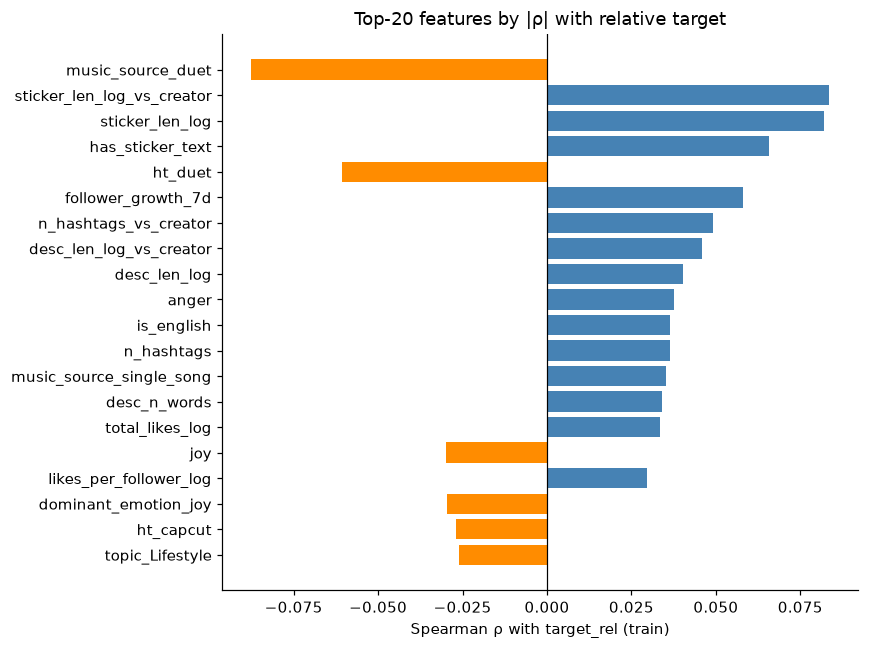

In [20]:
target_corr = (df.loc[TRAIN, FEATURES]
                 .corrwith(df.loc[TRAIN, "target_rel"], method="spearman")
                 .dropna().sort_values(key=np.abs, ascending=False))
top = target_corr.head(20)[::-1]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top.values, color=np.where(top.values > 0, "steelblue", "darkorange"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Spearman ρ with target_rel (train)")
ax.set_title("Top-20 features by |ρ| with relative target")
fig.tight_layout()
fig.savefig(FIGS / "nb03_feature_target_corr.png", dpi=120, bbox_inches="tight")
plt.show()

## Step 15. Leakage check

A feature with |ρ| > 0.5 with the target would suggest leakage. We also make sure no `engagement_daily` columns are used, and that the final matrix has no NaN or Inf values.

**Result:** all checks pass.

In [21]:
engagement_cols = set(engagement.columns) - {"video_id", "date"}
print("Features with |rho| > 0.5 vs target_rel:", target_corr[target_corr.abs() > 0.5].round(3).to_dict())
print("Engagement columns among features:", sorted(engagement_cols & set(FEATURES)))
print("NaN in final matrix:", int(df[FEATURES].isna().sum().sum()))
print("Inf in final matrix:", int(np.isinf(df[FEATURES].to_numpy(dtype=float)).sum()))

Features with |rho| > 0.5 vs target_rel: {}
Engagement columns among features: []
NaN in final matrix: 0
Inf in final matrix: 0


## Step 16. Save

The notebook writes three files to `data/processed/`. They are not committed to git.
- `features.parquet`: `video_id` and the 106 features.
- `dataset_index.parquet`: ids, split, both targets and `creator_baseline`.
- `feature_spec.json`: the feature list, the groups (used for grouping SHAP results later), the top hashtags and the category levels.

Later notebooks load everything with `fe.load_feature_table(PROCESSED)`.

In [22]:
spec = fe.save_feature_table(
    df, selection, PROCESSED,
    spec_extra={
        "target_day": TARGET_DAY,
        "main_target": "target_rel",
        "seed": cfg["seed"],
        "test_size": cfg["split"]["test_size"],
        "min_videos_per_creator": cfg["data"]["min_videos_per_creator"],
        "top_hashtags": HASHTAG_MAP,
        "categorical_levels": CATEGORICAL_LEVELS,
    },
)
data, spec = fe.load_feature_table(PROCESSED)
print(f"Saved {len(data):,} rows x {len(spec['features'])} features")
for name in ["features.parquet", "dataset_index.parquet", "feature_spec.json"]:
    print(f"{name:<24} {(PROCESSED / name).stat().st_size / 1_048_576:.1f} MB")
display(data.head())

Saved 200,616 rows x 106 features
features.parquet         29.2 MB
dataset_index.parquet    6.8 MB
feature_spec.json        0.0 MB


,video_id,author_id,split,create_dt,target_abs,target_rel,creator_baseline,duration_log,is_english,created_by_ai,...,music_source_shoot_page_search,music_source_single_song,music_source_unknown,music_source_video_capsule_recommend,dominant_emotion_anger,dominant_emotion_disgust,dominant_emotion_fear,dominant_emotion_joy,dominant_emotion_sadness,dominant_emotion_surprise
0,7385287868677377326,10245051,train,2024-06-27 15:48:55,6.068426,0.057158,6.011267,1.957698,1,0,...,0,0,0,0,0,0,0,1,0,0
1,7403462490908085550,10245051,train,2024-08-15 15:15:43,5.780744,-0.230524,6.011267,2.750599,0,0,...,0,0,0,0,0,0,0,1,0,0
2,7403888740294233386,10245051,test,2024-08-16 18:49:46,5.726848,-0.284419,6.011267,1.934416,0,0,...,0,0,0,0,0,0,0,1,0,0
3,7404157595373817134,10245051,train,2024-08-17 12:13:06,5.973810,-0.037458,6.011267,2.923162,0,0,...,0,0,0,0,0,0,0,0,0,1
4,7404714313518288174,10245051,train,2024-08-19 00:13:31,5.945421,-0.065847,6.011267,2.775460,0,0,...,0,0,0,0,0,0,0,1,0,0


## Copy to Google Drive (Colab only)

Colab deletes `/content` when the session ends. This cell copies the processed files to Google Drive, so the modelling notebooks can use them without re-running this one.

In [23]:
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_DIR = Path("/content/drive/MyDrive/creator_analytics/processed")
    DRIVE_DIR.mkdir(parents=True, exist_ok=True)
    for name in ["features.parquet", "dataset_index.parquet", "feature_spec.json"]:
        shutil.copy(PROCESSED / name, DRIVE_DIR / name)
    print("Copied to", DRIVE_DIR)

Mounted at /content/drive
Copied to /content/drive/MyDrive/creator_analytics/processed


## Summary and next steps

**Done:**
- **Feature table:** a leakage-safe table with 106 features in 14 groups for 200 616 videos and 1 437 creators.
- **Shared split:** the global and per-creator models will use the same split, which makes their comparison fair.

**Key decisions:**
- **Target:** relative target at day 14.
- **Followers:** taken as of the day before publishing.
- **Sounds and history:** past-only sound popularity and posting history.
- **Creator-relative features:** added for 7 key features (`*_vs_creator`).
- **Dropped:** the precomputed text statistics, because they are a data-collection artifact.

**Next:** baseline global model (notebook 04), then an ablation by feature group on a validation part of train, to see which groups actually improve the model.